# 05 — Validação

Como sabemos que o pipeline decide bem? Este notebook reúne os testes que um auditor pediria, no espírito da ASOP 56
(validar com dados não usados no ajuste e comparar com alternativas) e da ASOP 25 (credibilidade: resultados
razoáveis, sem viés material, com equilíbrio entre responsividade e estabilidade).

| Parte | Pergunta | Dados |
|---|---|---|
| 1 | A credibilidade prevê melhor que a média do mercado e que a experiência pura? | **reais**: SUSEP SES, seguradoras no ramo vida |
| 2 | Há choque ou tendência no tempo que a taxa manual precise tratar? | carteira |
| 3 | Excluir o ano de choque melhora a taxa manual? | carteira, teste fora do tempo |
| 4 | Qual credibilidade usar na renovação, com vários anos-alvo? | carteira, backtest fora do tempo |

Todas as comparações usam só informação disponível na data de cada previsão. Anos-alvo afetados pela pandemia ficam
fora da pontuação: nenhum método os prevê, e incluí-los só acrescenta ruído.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Memory
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import publicos as P, manual as M, avaliacao as A, estudo as S, backtest as B

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cr, cp = (carregar_config(n, RAIZ) for n in ("base", "manual", "renovacao", "publicos"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros", "premios")}
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
METODO = tabela["meta"]["modelo_escolhido"]
print("Método da taxa manual (03b):", METODO, "| anos excluídos da experiência:", cm["excluir_anos_experiencia"])

Método da taxa manual (03b): ridge com priori SOA | anos excluídos da experiência: [2021]


## 1. Credibilidade com dados reais: seguradoras no SES

Cada seguradora faz o papel de um grupo: a sinistralidade anual do ramo 0993 (sinistro ocorrido ÷ prêmio ganho) é a
experiência, e o prêmio ganho é o peso. Para cada ano-alvo, usando só os 5 anos anteriores, prevê-se a
sinistralidade de cada seguradora por três métodos:

$$
\hat{x}_i^{\text{mercado}} = \bar{x}, \qquad \hat{x}_i^{\text{própria}} = \bar{x}_i, \qquad
\hat{x}_i^{\text{BS}} = Z_i\,\bar{x}_i + (1 - Z_i)\,\bar{x}, \quad Z_i = \frac{w_i}{w_i + k},
$$

com $k$ de Bühlmann-Straub (`actuar::cm`) estimado nessa mesma janela. Pontuação: erro quadrático ponderado pelo
prêmio, só nos anos-alvo normais (2019, 2023, 2024, 2025); IC da diferença por bootstrap pareado.

In [2]:
ses = P.ler_ses(cp, RAIZ)
anual = P.sinistralidade_anual(ses[ses["ano"] <= 2025], "0993", por_cia=True)
anual = anual[anual["premio_ganho"] > 1e7].rename(columns={"coenti": "unidade", "sinistralidade": "x"})
anual["w"] = anual["premio_ganho"] / 1e6                       # em R$ milhões
ALVOS, PANDEMIA = list(range(2019, 2026)), (2020, 2021, 2022)
res = {pol: B.credibilidade_mercado(anual, ALVOS, 5, anos_excluidos_historico=exc, anos_alvo_excluidos=PANDEMIA, n_boot=2000)
       for pol, exc in [("manter 2020-2022 no histórico", ()), ("excluir 2020-2022 do histórico", PANDEMIA)]}
ses_res = pd.concat({p: r["resumo"].set_index("metodo") for p, r in res.items()}, names=["política", "método"])
ses_res.to_csv(RAIZ / "resultados/05_credibilidade_ses.csv")
ses_res

erro quadrático ponderado  \
política                       método                                           
manter 2020-2022 no histórico  Bühlmann-Straub                         0.0134   
                               experiência própria                     0.0139   
                               média da carteira                       0.0494   
excluir 2020-2022 do histórico Bühlmann-Straub                         0.0108   
                               experiência própria                     0.0107   
                               média da carteira                       0.0445   

                                                    dif. vs experiência própria  \
política                       método                                             
manter 2020-2022 no histórico  Bühlmann-Straub                          -0.0005   
                               experiência própria                       0.0000   
                               média da carteira                         0.0355   
excluir 2020-2022 do histórico Bühlmann-Straub                           0.0002   
                               experiência própria                       0.0000   
                               média da carteira                         0.0338   

                                                    IC95 inf  IC95 sup  
política                       método                                   
manter 2020-2022 no histórico  Bühlmann-Straub       -0.0018    0.0007  
                               experiência própria    0.0000    0.0000  
                               média da carteira      0.0216    0.0501  
excluir 2020-2022 do histórico Bühlmann-Straub       -0.0013    0.0012  
                               experiência própria    0.0000    0.0000  
                               média da carteira      0.0225    0.0466

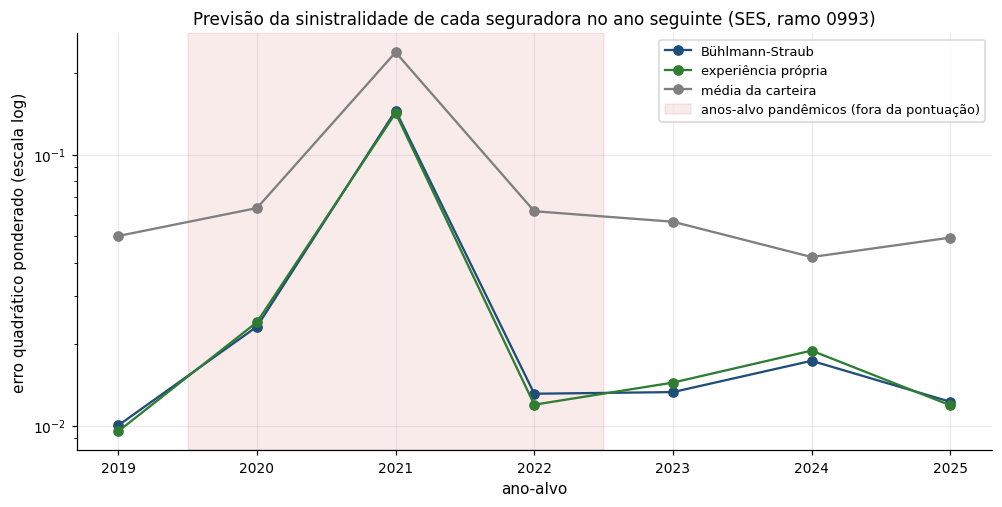

,Z mediano,k
ano_alvo,,
2019,0.8328,85.1007
2020,0.8625,67.0550
2021,0.8914,78.6048
2022,0.7335,221.5464
2023,0.7590,188.2987
2024,0.7947,144.5908
2025,0.7702,160.7977


In [3]:
d = res["manter 2020-2022 no histórico"]["detalhe"]
e = d.groupby(["ano_alvo", "metodo"]).apply(lambda g: np.average(g["erro2"], weights=g["w"]), include_groups=False).unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
for m, cor in zip(e.columns, ["#1f4e79", "#2e7d32", "#7f7f7f"]):
    ax.plot(e.index, e[m], "o-", color=cor, label=m)
ax.axvspan(2019.5, 2022.5, color="#c00000", alpha=0.08, label="anos-alvo pandêmicos (fora da pontuação)")
ax.set_yscale("log"); ax.set_xlabel("ano-alvo"); ax.set_ylabel("erro quadrático ponderado (escala log)")
ax.set_title("Previsão da sinistralidade de cada seguradora no ano seguinte (SES, ramo 0993)"); ax.legend()
plt.show()
z = d[d["metodo"] == "Bühlmann-Straub"].groupby("ano_alvo")[["Z", "k"]].agg({"Z": "median", "k": "first"})
z.rename(columns={"Z": "Z mediano"})

**Leitura:**
- A experiência própria erra **menos da metade** que a média do mercado: as seguradoras diferem de forma estrutural
  (carregamento, mix de coberturas e de produtos), e a experiência própria captura isso.
- Bühlmann-Straub fica praticamente igual à experiência própria, porque as seguradoras são grandes e o Z mediano é
  alto. É o resultado que a teoria prevê: com volume, a credibilidade vai para perto de 1.
- Os anos-alvo pandêmicos têm erro de outra ordem de grandeza para todos os métodos, e **tirar 2020–2022 do
  histórico** reduz o erro nos anos normais seguintes: a mesma política adotada para a taxa manual da carteira.
- Para unidades pequenas, como a maioria dos estipulantes de vida em grupo, Z é baixo e a credibilidade faz diferença
  (teste `test_credibilidade_mercado_favorece_credibilidade_com_unidades_pequenas` e parte 4).

## 2. A/E por ano-calendário na carteira: choque e tendência

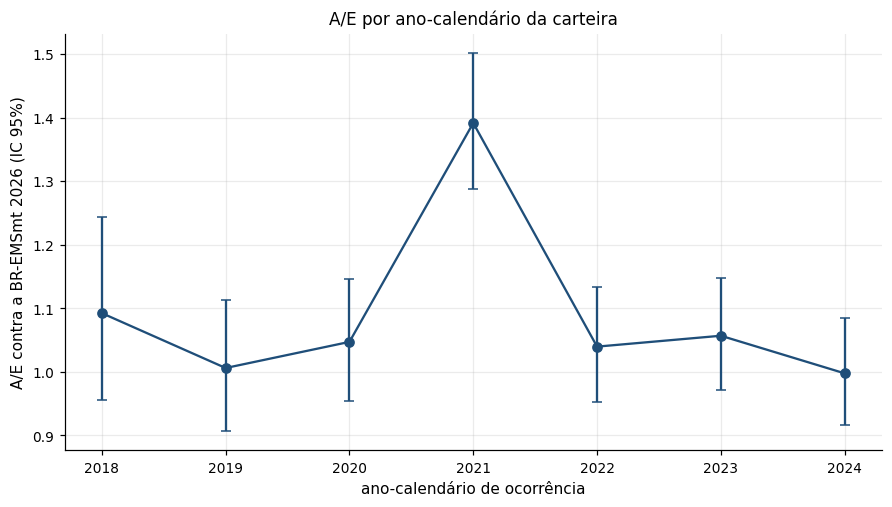

,ano,óbitos,esperados (tábua),A/E,IC inf,IC sup
0,2018,229,209.6481,1.0923,0.9554,1.2433
1,2019,373,370.7808,1.0060,0.9065,1.1134
2,2020,467,446.0052,1.0471,0.9542,1.1465
3,2021,658,472.9076,1.3914,1.2871,1.5019
4,2022,522,502.1084,1.0396,0.9523,1.1327
5,2023,558,528.0398,1.0567,0.9709,1.1482
6,2024,553,554.3435,0.9976,0.9162,1.0843


In [4]:
base = lambda janela, exc=(): M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                                                cfg["data_referencia"], cm, janela=janela, excluir_anos=exc)
linhas = []
for ano in range(2018, 2025):
    c, _ = base((f"{ano}-01-01", f"{ano}-12-31"))
    inf, sup = S.ic_poisson([c["N"].sum()])
    linhas.append({"ano": ano, "óbitos": c["N"].sum(), "esperados (tábua)": c["E"].sum(), "A/E": c["N"].sum() / c["E"].sum(),
                   "IC inf": inf[0] / c["E"].sum(), "IC sup": sup[0] / c["E"].sum()})
ae_ano = pd.DataFrame(linhas)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(ae_ano["ano"], ae_ano["A/E"], yerr=[ae_ano["A/E"] - ae_ano["IC inf"], ae_ano["IC sup"] - ae_ano["A/E"]],
            fmt="o-", color="#1f4e79", capsize=3)
ax.set_xlabel("ano-calendário de ocorrência"); ax.set_ylabel("A/E contra a BR-EMSmt 2026 (IC 95%)")
ax.set_title("A/E por ano-calendário da carteira"); plt.show()
ae_ano

O ano de 2021 fica fora do intervalo dos demais (choque pandêmico; no gerador é uma hipótese explícita, calibrada
pelo que o SES mostra no mercado). Fora dele, não há tendência que se distinga do ruído: os intervalos se sobrepõem.
Por isso não há fator de tendência na tarifa. Na base real, se este gráfico mostrar tendência, o ano-calendário
entra como variável do modelo.

## 3. Política para o ano de choque: excluir 2021 da experiência da taxa manual?

Mesma partição fora do tempo do 03b (treino até 2023, teste 2024) e o mesmo método da taxa manual; muda só a
experiência de treino.

In [5]:
te, _ = base(tuple(cm["fora_do_tempo"]["teste"]))
prev = {}
for nome, exc in [("manter 2021", ()), ("excluir 2021", (2021,))]:
    tr, i = base((None, cm["fora_do_tempo"]["treino_ate"]), exc)
    tab = cache(M.ajustar_tabela)(tr, METODO, cm, prioris, {})
    t2 = te.assign(cnae_secao=te["cnae_secao_original"].where(te["cnae_secao_original"].isin(set(tr["cnae_secao"])), "OUTRAS"),
                   capital=cm["capital_referencia"] * np.exp(te["log_capital_c"]))
    te[f"mu_{nome}"] = t2["E"] * M.multiplicador_manual(t2, tab)[0]
    prev[nome] = f"mu_{nome}"
comp = A.comparar_modelos(te, prev, "manter 2021", unidade="id_estipulante")
comp["A/M total no teste"] = [te["N"].sum() / te[c].sum() for c in prev.values()]
comp

,modelo,deviance,diferença vs manter 2021,IC95 inf,IC95 sup,significativa,A/M total no teste
0,manter 2021,329.4188,0.0000,0.0000,0.0000,False,0.8943
1,excluir 2021,323.2179,-6.2009,-14.0337,1.9828,False,0.9511


Excluir 2021 reduz a deviance no teste e, principalmente, o **viés de nível**: com 2021, a taxa manual superestima
2024 bem mais. A diferença de deviance não é significativa com um ano de teste, mas aponta na mesma direção da evidência
real (SES) e do A/E por ano. Decisão: `excluir_anos_experiencia: [2021]` em `config/manual.yaml`, aplicada no 03b.

## 4. Backtest da renovação com vários anos-alvo

Para cada ano-alvo $Y$, a taxa manual é estimada com o mesmo método do 03b, só com a experiência até $Y$ menos a
maturação, e o $k$ de Bühlmann-Straub vem da carteira no início de $Y$. Ficam fora os anos-apólice que começam em
2020 ou 2021, porque atravessam o ano pandêmico.

In [6]:
def tabela_ate(data):
    c, i = base((None, data), tuple(cm["excluir_anos_experiencia"]))
    return M.ajustar_tabela(c, METODO, cm, prioris, i)

ANOS = [2019, 2022, 2023, 2024]
bt = cache(B.executar_varios_anos)(dados, tabua, tabela_ate, cr, cfg["data_referencia"], ANOS)
print("Anos-alvo por ano de início:", bt["por_grupo"]["ano_alvo"].value_counts().sort_index().to_dict(),
      "| k de Bühlmann-Straub por ano:", {a: round(k, 1) for a, k in bt["k_por_ano"].items()})
bt["comparacao_deviance"].to_csv(RAIZ / "resultados/05_backtest_renovacao.csv", index=False)
bt["comparacao_deviance"]

Anos-alvo por ano de início: {2019: 173, 2022: 250, 2023: 250, 2024: 17} | k de Bühlmann-Straub por ano: {2019: 2.7, 2022: 18.6, 2023: 5.9, 2024: 16.7}


,método,deviance,diferença vs só manual,IC95 inf,IC95 sup
0,Só taxa manual (Z = 0),"1,417.5960",0.0000,0.0000,0.0000
1,"Credibilidade de mercado (raiz, vidas-ano)",905.9156,-511.6804,-707.6929,-345.8258
2,Bühlmann-Straub (n efetivo),969.2973,-448.2987,-621.2473,-303.1252
3,Só experiência (Z = 1),"1,209.8687",-207.7273,-452.4005,21.4977


In [7]:
bt["resumo"]

,método,deviance (contagem),erro relativo (valor limitado),previsto/observado (valor limitado),S/P carteira,dispersão da S/P entre grupos
0,Só taxa manual (Z = 0),"1,417.5960",0.0621,0.6873,0.9563,1.3547
1,"Credibilidade de mercado (raiz, vidas-ano)",905.9156,0.0404,0.9274,0.7138,0.9487
2,Bühlmann-Straub (n efetivo),969.2973,0.0447,0.8434,0.7833,1.0438
3,Só experiência (Z = 1),"1,209.8687",0.0402,1.0400,0.6380,2.5308
4,Regra contratual 75/85% (prêmio efetivamente c...,NaN,NaN,NaN,0.5373,0.6702


**Leitura:** com vários anos-alvo empilhados, a comparação tem mais poder que com um só (notebook 04). A conclusão
de qual credibilidade usar sai desta tabela: o método cujo IC da diferença contra "só taxa manual" fica abaixo de
zero ganha com significância; se nenhum ficar, a escolha volta à ordem de preferência (Bühlmann-Straub, por usar o
número efetivo e um $k$ estimado nos dados).

## Conclusões e o que mudou no pipeline
- **Credibilidade (dados reais):** a experiência própria e Bühlmann-Straub superam com folga a média do mercado; a
  credibilidade se ajusta ao volume como a teoria prevê.
- **Ano de choque:** 2021 sai da experiência da taxa manual (`config/manual.yaml`).
- **Tendência:** não há sinal fora do choque; sem fator de tendência.
- **Renovação:** com vários anos-alvo, a credibilidade (de mercado ou Bühlmann-Straub) prevê significativamente
  melhor que só a taxa manual, e só a experiência é significativamente pior. Entre as duas credibilidades a diferença
  não é significativa; fica Bühlmann-Straub (k estimado nos dados e peso pelo número efetivo).

**Limitações:** o SES mede sinistralidade com carregamento e todas as coberturas, por seguradora (não por
estipulante); na carteira, os anos de choque e os efeitos são hipóteses do gerador. Na base real, os mesmos testes
rodam sem mudança de código.